# 1. Data Processing and Data Cleaning

### (1) Input and organize the tornados dataset
  - Import our dataset that has all tornadoes between 1950 and 2025 into a variable named tornados_df

In [51]:
# import modules
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# read the file into tornados_df
tornados_df = pd.read_csv('data/1950-2025_all_tornadoes.csv', low_memory=False)

  - Import the file decription
  (based on the SPC file description: https://www.spc.noaa.gov/wcm/data/SPC_severe_database_description.pdf)

In [3]:
desc = pd.read_csv('data/spc_tornado_codebook_up.csv')

  - Quick check for the dataset

In [4]:
display(tornados_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74956 entries, 0 to 74955
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   om      74956 non-null  object 
 1   yr      74956 non-null  int64  
 2   mo      74956 non-null  int64  
 3   dy      74956 non-null  int64  
 4   date    74956 non-null  object 
 5   time    74956 non-null  object 
 6   tz      74956 non-null  int64  
 7   st      74956 non-null  object 
 8   stf     74956 non-null  int64  
 9   stn     74956 non-null  int64  
 10  mag     74956 non-null  int64  
 11  inj     74956 non-null  int64  
 12  fat     74956 non-null  int64  
 13  loss    74956 non-null  float64
 14  closs   74956 non-null  float64
 15  slat    74956 non-null  float64
 16  slon    74956 non-null  float64
 17  elat    74956 non-null  float64
 18  elon    74956 non-null  float64
 19  len     74956 non-null  float64
 20  wid     74956 non-null  int64  
 21  ns      74956 non-null  int64  
 22

None

In [5]:
display(tornados_df.describe(include='all'))

,om,yr,mo,dy,date,time,tz,st,stf,stn,...,ns,sn,sg,f1,f2,f3,f4,fc,edat,etime
count,74956,74956.000000,74956.000000,74956.000000,74956,74956,74956.000000,74956,74956.000000,74956.000000,...,74956.000000,74956.000000,74956.000000,74956.000000,74956.000000,74956.000000,74956.000000,74956.000000,24880,24880
unique,26698,NaN,NaN,NaN,12998,1438,NaN,53,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3276,1439
top,124,NaN,NaN,NaN,2011-04-27,16:00:00,NaN,TX,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2011-04-27,17:35:00
freq,67,NaN,NaN,NaN,234,1004,NaN,9681,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,236,74
mean,NaN,1993.987059,5.932134,15.932894,NaN,NaN,3.000881,NaN,29.042705,19.490741,...,1.028123,0.989194,0.999440,103.792972,9.328433,1.863306,0.595576,0.024868,NaN,NaN
std,NaN,20.519378,2.459246,8.784929,NaN,NaN,0.069297,NaN,14.974762,30.282875,...,0.169942,0.103391,0.452654,95.399037,39.662910,17.441124,9.733466,0.155724,NaN,NaN
min,NaN,1950.000000,1.000000,1.000000,NaN,NaN,0.000000,NaN,1.000000,0.000000,...,0.000000,0.000000,-9.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,NaN,1977.000000,4.000000,8.000000,NaN,NaN,3.000000,NaN,18.000000,0.000000,...,1.000000,1.000000,1.000000,37.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
50%,NaN,1997.000000,6.000000,16.000000,NaN,NaN,3.000000,NaN,28.000000,7.000000,...,1.000000,1.000000,1.000000,85.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
75%,NaN,2011.000000,7.000000,24.000000,NaN,NaN,3.000000,NaN,42.000000,26.000000,...,1.000000,1.000000,1.000000,135.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN


### (2) Data Cleaning

#### 1. Multiple tornadoes

- A tornado can appear in several rows in this dataset. According to the file description, the number of unique tornadoes can be determined by considering the "ns", "sn", and "sg" variables.

   - ns: Number of states affected by this tornado (1, 2, 3)
   - sn: Whether entire track infomation in this row
     - 1: complete information
     - 0: else
   - sg: Types of rows
     - 1: Entire track information
     - 2: Segments by state
     - -9: Additional counties
- According to this information, rows where sg == 1 summarize the entire path of a tornado; therefore, the number of unique tornadoes can be determined by counting the rows where sg == 1.

In [6]:
tornados_df.groupby(["ns", "sn", "sg"])["sg"].count()

ns  sn  sg
0   0   -9        1
1   0   -9      115
    1    1    72788
2   0   -9       23
         1      656
    1    2     1316
3   0   -9        1
         1       14
    1    2       42
Name: sg, dtype: int64

- According to the groupby results (all years), there were 72,788 single-state tornadoes (1,1,1), 656 two-state tornadoes (2,0,1), and 14 three-state tornadoes (3,0,1). The rows with sg = 2 are state segments of those multi-state tornadoes, and the rows with sg = -9 only list additional counties.
- Delete rows where the variable 'ns' is 0. (ns must be 1, 2, 3)

In [7]:
tornados_df.drop(tornados_df[tornados_df["ns"] == 0].index, inplace = True)
tornados_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 74955 entries, 0 to 74955
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   om      74955 non-null  object 
 1   yr      74955 non-null  int64  
 2   mo      74955 non-null  int64  
 3   dy      74955 non-null  int64  
 4   date    74955 non-null  object 
 5   time    74955 non-null  object 
 6   tz      74955 non-null  int64  
 7   st      74955 non-null  object 
 8   stf     74955 non-null  int64  
 9   stn     74955 non-null  int64  
 10  mag     74955 non-null  int64  
 11  inj     74955 non-null  int64  
 12  fat     74955 non-null  int64  
 13  loss    74955 non-null  float64
 14  closs   74955 non-null  float64
 15  slat    74955 non-null  float64
 16  slon    74955 non-null  float64
 17  elat    74955 non-null  float64
 18  elon    74955 non-null  float64
 19  len     74955 non-null  float64
 20  wid     74955 non-null  int64  
 21  ns      74955 non-null  int64  
 22  sn 

- To conduct a unique tornado analysis, we must drop all rows except those where "sg == 1"; however, doing so would result in the loss of county information.
- Since we need to merge this with data such as population figures later, we must create a separate DataFrame that records the counties passed by each individual tornado.
- This step will be performed at the very end of the data cleaning process.

#### 2. Time period of analysis

- Previous study indicates that the number of observed tornadoes increased following the completion of radar installations for tornado detection in 1995. It is necessary to verify this and determine the time period for the dataset to be used in the analysis.

In [8]:
cnt = tornados_df.groupby(["yr"])["sg"].apply(lambda x: x[x == 1].count()).reset_index()

cnt["period"] = cnt["yr"] >= 1995
cnt.groupby("period")["sg"].mean().reset_index()

# before 1995: False / after 1995: True

,period,sg
0,False,759.866667
1,True,1266.580645


- The average annual number of tornadoes showed a significant difference between the periods before and after 1995, with 760 and 1,267 tornadoes, respectively. Therefore, we are going to use only the data after 1995.

In [9]:
new_tornados_df = tornados_df[tornados_df["yr"] >= 1995].copy()
new_tornados_df.describe()

,yr,mo,dy,tz,stf,stn,mag,inj,fat,loss,...,len,wid,ns,sn,sg,f1,f2,f3,f4,fc
count,40205.000000,40205.000000,40205.000000,40205.0,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,4.020500e+04,...,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.0
mean,2010.266982,5.904390,16.162045,3.0,28.078672,13.189578,0.223156,0.822286,0.066634,9.550544e+05,...,3.439134,144.028131,1.034175,0.987788,1.009178,100.870688,9.720308,1.609004,0.451113,0.0
std,9.057967,2.584289,8.860605,0.0,14.927819,27.195685,2.011260,12.925578,1.285258,2.895273e+07,...,6.529076,245.768468,0.186544,0.109834,0.389061,90.890861,39.841133,16.410123,8.367417,0.0
min,1995.000000,1.000000,1.000000,3.0,1.000000,0.000000,-9.000000,0.000000,0.000000,0.000000e+00,...,0.000000,0.000000,1.000000,0.000000,-9.000000,0.000000,0.000000,0.000000,0.000000,0.0
25%,2003.000000,4.000000,8.000000,3.0,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,...,0.280000,30.000000,1.000000,1.000000,1.000000,39.000000,0.000000,0.000000,0.000000,0.0
50%,2010.000000,5.000000,16.000000,3.0,28.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,...,1.120000,50.000000,1.000000,1.000000,1.000000,83.000000,0.000000,0.000000,0.000000,0.0
75%,2018.000000,7.000000,24.000000,3.0,40.000000,14.000000,1.000000,0.000000,0.000000,1.000000e+04,...,4.000000,150.000000,1.000000,1.000000,1.000000,133.000000,0.000000,0.000000,0.000000,0.0
max,2025.000000,12.000000,31.000000,3.0,78.000000,232.000000,5.000000,1500.000000,158.000000,2.800102e+09,...,168.530000,4576.000000,3.000000,1.000000,2.000000,810.000000,820.000000,710.000000,437.000000,0.0


#### 3. Remove unncessary columns

- "tz" (time zone) are all 3, so drop this column
- "fc" (f-scale changed flag) are all 0, so drop this column
- "edat" and "etime" appear only in data after 2007, so drop these columns
- "stn" is number of this tornado in this state in this year, but it discontinued in 2008. We drop this column.

In [10]:
new_tornados_df = new_tornados_df.drop(columns=["tz", "fc", "edat", "etime", "stn"])
new_tornados_df.describe()

,yr,mo,dy,stf,mag,inj,fat,loss,closs,slat,...,elon,len,wid,ns,sn,sg,f1,f2,f3,f4
count,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,4.020500e+04,4.020500e+04,40205.000000,...,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000
mean,2010.266982,5.904390,16.162045,28.078672,0.223156,0.822286,0.066634,9.550544e+05,6.035615e+03,37.110849,...,-89.740908,3.439134,144.028131,1.034175,0.987788,1.009178,100.870688,9.720308,1.609004,0.451113
std,9.057967,2.584289,8.860605,14.927819,2.011260,12.925578,1.285258,2.895273e+07,2.108153e+05,5.117238,...,16.856074,6.529076,245.768468,0.186544,0.109834,0.389061,90.890861,39.841133,16.410123,8.367417
min,1995.000000,1.000000,1.000000,1.000000,-9.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,...,-163.530000,0.000000,0.000000,1.000000,0.000000,-9.000000,0.000000,0.000000,0.000000,0.000000
25%,2003.000000,4.000000,8.000000,17.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,33.334900,...,-97.584200,0.280000,30.000000,1.000000,1.000000,1.000000,39.000000,0.000000,0.000000,0.000000
50%,2010.000000,5.000000,16.000000,28.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,37.006500,...,-91.930000,1.120000,50.000000,1.000000,1.000000,1.000000,83.000000,0.000000,0.000000,0.000000
75%,2018.000000,7.000000,24.000000,40.000000,1.000000,0.000000,0.000000,1.000000e+04,0.000000e+00,40.763200,...,-85.913500,4.000000,150.000000,1.000000,1.000000,1.000000,133.000000,0.000000,0.000000,0.000000
max,2025.000000,12.000000,31.000000,78.000000,5.000000,1500.000000,158.000000,2.800102e+09,2.352000e+07,61.130000,...,0.000000,168.530000,4576.000000,3.000000,1.000000,2.000000,810.000000,820.000000,710.000000,437.000000


#### 4. Length and width

- Since a tornado's length and width cannot be zero, they must be checked.

In [11]:
len_0 = new_tornados_df[(new_tornados_df["len"] == 0)]
display(len(len_0))
wid_0 = new_tornados_df[(new_tornados_df["wid"] == 0)]
display(len(wid_0))

175

530

In [12]:
display(len_0.groupby(["mag"])["mag"].count())
display(wid_0.groupby(["mag"])["mag"].count())

mag
0    169
1      5
4      1
Name: mag, dtype: int64

mag
0    429
1     73
2     17
3     10
4      1
Name: mag, dtype: int64

- There are 530 rows with a width of 0 and 175 with a length of 0. Considering the magnitude values ​​as well, these appear to be missing values.
- They are included in the overall analysis but excluded from analyses requiring width and length data.

#### 5. Unknown magnitude

- Unknown magnitude (mag == -9)

   - Magnitude is crucial in the analysis; we must determine whether to include rows with unknown magnitudes.

In [13]:
new_tornados_df.groupby("mag")["mag"].count()

mag
-9     1560
 0    21604
 1    12475
 2     3399
 3      946
 4      204
 5       17
Name: mag, dtype: int64

- Since the number of rows have unknown magnitude are 1,560, we cannot drop these rows.
- Check the average length and width for each grade

In [14]:
display(new_tornados_df.groupby("mag")["len"].mean())
display(new_tornados_df.groupby("mag")["wid"].mean())

mag
-9     1.246192
 0     1.373635
 1     4.214658
 2     8.890850
 3    17.863964
 4    30.655490
 5    41.143529
Name: len, dtype: float64

mag
-9      47.955769
 0      58.164738
 1     184.177555
 2     373.944984
 3     689.079281
 4    1037.725490
 5    1590.000000
Name: wid, dtype: float64

- The average length and width of the "EF unknown" tornado were smaller than those of the EF0 tornado. This suggests that the "EF unknown" tornadoes were likely too small for an accurate damage rating to be assigned.
- We should maintain these rows, but we must be careful when performing regression analysis.

#### 6. "loss" and "closs"

- According to the file documentation, loss and closs changes units over time: category codes in 1995, millions of dollars in 1996–2006, and dollars from 2007. A value of 0 does not mean no loss. These are good variables to refer to along with casualty analysis, but if 0 is not an accurate value, there is a possibility of incorrect analysis.
- Therefore, these two variables will be excluded from the analysis.

In [15]:
new_tornados_df = new_tornados_df.drop(columns=["loss", "closs"])
new_tornados_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40205 entries, 34750 to 74955
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   om      40205 non-null  object 
 1   yr      40205 non-null  int64  
 2   mo      40205 non-null  int64  
 3   dy      40205 non-null  int64  
 4   date    40205 non-null  object 
 5   time    40205 non-null  object 
 6   st      40205 non-null  object 
 7   stf     40205 non-null  int64  
 8   mag     40205 non-null  int64  
 9   inj     40205 non-null  int64  
 10  fat     40205 non-null  int64  
 11  slat    40205 non-null  float64
 12  slon    40205 non-null  float64
 13  elat    40205 non-null  float64
 14  elon    40205 non-null  float64
 15  len     40205 non-null  float64
 16  wid     40205 non-null  int64  
 17  ns      40205 non-null  int64  
 18  sn      40205 non-null  int64  
 19  sg      40205 non-null  int64  
 20  f1      40205 non-null  int64  
 21  f2      40205 non-null  int64  
 22 

#### 7. Contiguous United States data

- We keep only tornadoes in the contiguous United States (CONUS) and exclude those in Alaska, Hawaii, Puerto Rico, and the U.S. Virgin Islands.

In [16]:
new_tornados_df = new_tornados_df[~new_tornados_df["st"].isin(["AK", "HI", "PR", "VI"])].copy()

#### 8. Create a Tornado-County linkage DataFrame

- Each row is one (tornado, county) pair, so a tornado that crossed three counties has three rows.
- Counties of multi-state tornadoes are only in the state-segment rows (sg = 2, -9), so we link those rows to their whole-track row before keeping sg == 1.
- To link the tornado and county data, we need to find a key that identifies the same tornado. According to the file documentation, it appears possible to create this key by combining "om" and "yr".
- In the case of "om," the format changed starting in 2007, and the file documentation states that segments of a tornado crossing state borders and/or spanning more than four counties share the same "om" (see ns/sn/sg).
- Accordingly, we first select the rows where sg == 1 and check whether the combination of "om" and "yr" is unique.

In [17]:
# wdf: whole route df
wdf = new_tornados_df[new_tornados_df["sg"] == 1].copy()
wdf["tor_id"] = wdf.index
wdf["idx"] = wdf["yr"].astype(str) + wdf["om"].astype(str)
wdf["idx"].is_unique

False

- Since "idx" is not unique, we have to find duplicated rows.

In [18]:
wdf[wdf.duplicated(["idx"], keep=False)].sort_values(["idx"])

,om,yr,mo,dy,date,time,st,stf,mag,inj,...,wid,ns,sn,sg,f1,f2,f3,f4,tor_id,idx
35175,9999,1995,5,13,1995-05-13,15:18:00,IL,17,4,7,...,1000,1,1,1,67,71,187,0,35175,19959999
35519,9999,1995,5,9,1995-05-09,16:17:00,IA,19,1,0,...,50,1,1,1,163,0,0,0,35519,19959999
42528,56,2001,3,15,2001-03-15,03:30:00,FL,12,2,21,...,350,1,1,1,133,63,0,0,42528,200156
42529,56,2001,3,15,2001-03-15,03:40:00,FL,12,2,0,...,300,1,1,1,63,0,0,0,42529,200156
43767,506,2002,4,11,2002-04-11,16:19:00,KS,20,0,0,...,220,1,1,1,155,0,0,0,43767,2002506
43768,506,2002,4,11,2002-04-11,16:35:00,KS,20,0,0,...,110,1,1,1,95,0,0,0,43768,2002506


- Three pairs share the same idx but have different dates, times, or counties, so they are different tornadoes. All six are single-state tornadoes with no segment rows.
- We keep all of them and modify their idx.

In [19]:
wdf.loc[35519, "idx"] = "19959999-2"
wdf.loc[42529, "idx"] = "200156-2"
wdf.loc[43768, "idx"] = "2002506-2"
wdf["idx"].is_unique

True

- Now, we merge the whole dataframe (sg==1) with the segment dataframe (sg != 1).

In [20]:
# sdf: segment df
sdf = new_tornados_df[new_tornados_df["sg"] != 1].copy()
sdf["idx"] = sdf["yr"].astype(str) + sdf["om"].astype(str)
print(len(sdf))
m_df = sdf.merge(wdf,
                 on = "idx", how = "left",
                 suffixes=("", "_whole"),
                 indicator = True,
                 validate="many_to_one")
m_df["_merge"].value_counts()

941


_merge
left_only     718
both          223
right_only      0
Name: count, dtype: int64

- Out of a total of 941 items, 718 failed to find a match. This shows that a key cannot be created simply by merging "yr" and "om". We need to examine a few of the "left-only" rows to determine the proper way to make the key.

In [21]:
display(m_df[m_df["yr"] == 1997])
display(m_df[m_df["yr"] == 2020])

,om,yr,mo,dy,date,time,st,stf,mag,inj,...,wid_whole,ns_whole,sn_whole,sg_whole,f1_whole,f2_whole,f3_whole,f4_whole,tor_id,_merge
24,558,1997,10,25,1997-10-25,16:10:00,MS,28,1,7,...,300.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,37234.0,both
25,558,1997,10,25,1997-10-25,17:10:00,AL,1,1,0,...,300.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,37234.0,both
26,454,1997,6,17,1997-06-17,18:13:00,TN,47,1,0,...,30.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,37930.0,both
27,454,1997,6,17,1997-06-17,18:23:00,KY,21,1,2,...,30.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,37930.0,both
28,903,1997,7,3,1997-07-03,17:20:00,NY,36,2,0,...,100.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,38190.0,both
29,903,1997,7,3,1997-07-03,17:22:00,MA,25,2,0,...,100.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,38190.0,both


,om,yr,mo,dy,date,time,st,stf,mag,inj,...,wid_whole,ns_whole,sn_whole,sg_whole,f1_whole,f2_whole,f3_whole,f4_whole,tor_id,_merge
642,2001110333-03,2020,1,11,2020-01-11,03:33:00,AR,5,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
643,2001110333-01,2020,1,11,2020-01-11,03:44:00,MS,28,2,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
644,2003241627-02,2020,3,24,2020-03-24,16:27:00,MS,28,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
645,2003241627-03,2020,3,24,2020-03-24,16:39:00,AL,1,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
646,2003281918-02,2020,3,28,2020-03-28,19:18:00,KY,21,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
647,2003281918-03,2020,3,28,2020-03-28,19:19:00,IN,18,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
648,2003311034-02,2020,3,31,2020-03-31,10:34:00,AL,1,2,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
649,2003311034-03,2020,3,31,2020-03-31,10:46:00,GA,13,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
650,2004121512-02,2020,4,12,2020-04-12,15:12:00,MS,28,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
651,2004121536-02,2020,4,12,2020-04-12,15:36:00,MS,28,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only


- Comparing the results of 1997 and 2020, all connections were successful in 1997, but none were connected in 2020. This appears to be related to the format change of "om" in 2007. Connection status must be checked by year.

In [22]:
# not connected
g = m_df[m_df["_merge"] == "left_only"]["yr"].reset_index()
display(g.groupby("yr").count().T)

# after 2007 - all results
k = m_df[m_df["yr"] > 2006]["yr"].reset_index()
display(k.groupby("yr").count().T)

yr,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
index,13,46,23,34,74,17,32,21,31,14,45,19,50,33,50,26,40,82,68


yr,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
index,13,46,23,34,74,17,32,21,31,14,45,19,50,33,50,26,40,82,68


- Based on these two results, we can confirm that none of the rows after 2007 are connected. We need to verify the format of "om".

In [23]:
df_2007 = new_tornados_df[(new_tornados_df["yr"] == 2007) & (new_tornados_df["ns"] == 2)]
df_2007 = df_2007.sort_values("om")
df_2007.head(6)

,om,yr,mo,dy,date,time,st,stf,mag,inj,...,elon,len,wid,ns,sn,sg,f1,f2,f3,f4
50415,0703011352-01,2007,3,1,2007-03-01,13:52:00,AL,1,1,2,...,-85.0396,30.84,150,2,0,1,0,0,0,0
50416,0703011352-02,2007,3,1,2007-03-01,13:52:00,AL,1,1,2,...,-85.0984,22.99,150,2,1,2,67,0,0,0
50418,0703011352-03,2007,3,1,2007-03-01,14:24:00,GA,13,0,0,...,-85.0396,7.85,100,2,1,2,61,239,0,0
50430,0703011727-01,2007,3,1,2007-03-01,17:27:00,AL,1,2,1,...,-84.8715,11.74,300,2,0,1,0,81,0,0
50431,0703011727-02,2007,3,1,2007-03-01,17:27:00,AL,1,1,0,...,-85.0066,2.31,100,2,1,2,113,81,0,0
50433,0703011727-03,2007,3,1,2007-03-01,17:31:00,GA,13,2,1,...,-84.8715,9.43,300,2,1,2,215,0,0,0


- The results above represent two tornadoes that affected two states in 2007. Looking at the 'om' field, the first ten characters are identical, while '01', '02', and '03' have been appended to distinguish between them.
- Now we can make the key with the first 10 digit of "om" for the data after 2007. We also have to check the uniqueness of these keys before using.

In [24]:
wdf["idx"] = wdf["yr"].astype(str) + wdf["om"].astype(str).where(wdf["yr"] < 2007, wdf["om"].str[:10])
wdf.loc[35519, "idx"] = "19959999-2"
wdf.loc[42529, "idx"] = "200156-2"
wdf.loc[43768, "idx"] = "2002506-2"
wdf["idx"].is_unique

False

- The keys are not unique either. We need to check for duplicate data.

In [25]:
dup = wdf[wdf.duplicated(["idx"], keep=False)].sort_values(["idx"])
display(dup.head(6))
display(dup["idx"].nunique())

,om,yr,mo,dy,date,time,st,stf,mag,inj,...,wid,ns,sn,sg,f1,f2,f3,f4,tor_id,idx
50295,0703241735-01,2007,3,24,2007-03-24,17:35:00,CO,8,0,0,...,50,1,1,1,115,0,0,0,50295,20070703241735
50296,0703241735-02,2007,3,24,2007-03-24,17:35:00,NE,31,0,0,...,10,1,1,1,101,0,0,0,50296,20070703241735
50316,0703281703-02,2007,3,28,2007-03-28,17:03:00,TX,48,0,0,...,220,1,1,1,45,0,0,0,50316,20070703281703
50315,0703281703-01,2007,3,28,2007-03-28,17:03:00,TX,48,0,0,...,50,1,1,1,153,0,0,0,50315,20070703281703
50323,0703281805-01,2007,3,28,2007-03-28,18:05:00,TX,48,0,0,...,200,1,1,1,129,0,0,0,50323,20070703281805
50324,0703281805-02,2007,3,28,2007-03-28,18:05:00,KS,20,0,0,...,25,1,1,1,39,0,0,0,50324,20070703281805


619

- -01 and -02 are used to distinguish between tornadoes that occurred at the same time, and also to distinguish between state sections of the same tornado. Since there are two ways for generating "om", duplication occurs.
- However, tornadoes that passed through only a single state are irrelevant to the merging process, so we can disregard them; we only need to check the duplicate rows that contain segment information.

In [26]:
# making the same key in segment dataframe
sdf["idx"] = sdf["yr"].astype(str) + sdf["om"].astype(str).where(sdf["yr"] < 2007, sdf["om"].str[:10])

# check the duplicated idx from segment dataframe
dup_seg = dup[dup["idx"].isin(sdf["idx"])]
display(dup_seg["idx"].nunique())
display(dup_seg)

23

,om,yr,mo,dy,date,time,st,stf,mag,inj,...,wid,ns,sn,sg,f1,f2,f3,f4,tor_id,idx
51473,0802051732-02,2008,2,5,2008-02-05,17:32:00,MS,28,2,13,...,440,2,0,1,0,0,0,0,51473,20080802051732
51472,0802051732-01,2008,2,5,2008-02-05,17:32:00,TN,47,1,0,...,50,1,1,1,167,0,0,0,51472,20080802051732
52995,0910291413-02,2009,10,29,2009-10-29,14:13:00,AR,5,1,0,...,1050,1,1,1,103,13,103,13,52995,20090910291413
52994,0910291413-01,2009,10,29,2009-10-29,14:13:00,AR,5,1,0,...,75,1,1,1,139,0,0,0,52994,20090910291413
54783,1005231952-01,2010,5,23,2010-05-23,19:52:00,KS,20,0,0,...,10,1,1,1,181,0,0,0,54783,20101005231952
54784,1005231952-02,2010,5,23,2010-05-23,19:52:00,NM,35,2,0,...,440,2,0,1,0,0,0,0,54784,20101005231952
55420,1008071725-02,2010,8,7,2010-08-07,17:25:00,ND,38,4,0,...,600,2,0,1,0,0,0,0,55420,20101008071725
55419,1008071725-01,2010,8,7,2010-08-07,17:25:00,MN,27,0,0,...,25,1,1,1,167,0,0,0,55419,20101008071725
56048,1104221859-01,2011,4,22,2011-04-22,18:59:00,OK,40,1,0,...,30,1,1,1,87,0,0,0,56048,20111104221859
56049,1104221859-02,2011,4,22,2011-04-22,18:59:00,MO,29,4,5,...,880,2,0,1,0,510,0,0,56049,20111104221859


- This result shows the duplicate idx pairs within the sdf dataframe that need to be connected.
- In 20 of the 23 cases, one tornado has ns = 1 and the other has ns = 2, and the segment rows (ns = 2) belong to the second. Adding ns to the key resolves these.
- The 3 cases (idx == 20090910291413, 20111104251748, 20111104270129, 6 rows) are ambiguous to connect which rows in the segment dataframe. We can simply check these rows in the segment dataframe.

In [27]:
display(sdf[sdf["idx"].isin(["20090910291413", "20111104251748", "20111104270129"])])

,om,yr,mo,dy,date,time,st,stf,mag,inj,...,len,wid,ns,sn,sg,f1,f2,f3,f4,idx
52996,0910291413-03,2009,10,29,2009-10-29,14:13:00,AR,5,0,0,...,0.0,0,1,0,-9,103,0,0,0,20090910291413
56112,1104251748-03,2011,4,25,2011-04-25,17:48:00,AR,5,0,0,...,0.0,0,1,0,-9,145,0,0,0,20111104251748
56218,1104270129-03,2011,4,27,2011-04-27,01:29:00,MS,28,0,0,...,0.0,0,1,0,-9,95,0,0,0,20111104270129


- These rows are additional county rows(sg = -9), containing information for a county. There is a value only in f1.
- If we delete these rows(and we lose only one county information for these 3 tornadoes), the duplication issue will not occur.

In [28]:
sdf = sdf[~sdf["idx"].isin(["20090910291413", "20111104251748", "20111104270129"])].copy()

- Finally, we merge wdf with sdf on key "idx" and "ns".

In [29]:
display(sdf.shape)

m_df = sdf.merge(wdf,
                 on = ["idx", "ns"], how = "left",
                 suffixes=("", "_whole"),
                 indicator = True,)
m_df["_merge"].value_counts()

(938, 25)

_merge
both          938
left_only       0
right_only      0
Name: count, dtype: int64

- Since the number of rows in "sdf" and "m_df" is the same, we can see that the merge was performed correctly.
- Now we will combine "wdf" and "m_df" to get county information for every tornado.

In [30]:
links = pd.concat([
    wdf[["tor_id", "stf", "f1", "f2", "f3", "f4"]],
    m_df[["tor_id", "stf", "f1", "f2", "f3", "f4"]]
], ignore_index=True)

links

,tor_id,stf,f1,f2,f3,f4
0,34750,51,153,0,0,0
1,34751,24,3,0,0,0
2,34752,24,13,0,0,0
3,34753,12,99,0,0,0
4,34754,24,21,0,0,0
...,...,...,...,...,...,...
40152,74737,48,111,0,0,0
40153,74752,13,105,0,0,0
40154,74752,45,65,0,0,0
40155,74889,38,35,0,0,0


- To link additional data later, a dataframe is created in which each Tornado ID is associated with a single county.

In [31]:
# melt
tc = links.melt(id_vars=["tor_id", "stf"],
                 value_vars=["f1", "f2", "f3", "f4"],
                value_name="county")
# drop rows that county code == 0
tc = tc[tc["county"] > 0].copy()

tc["fips"] = (tc["stf"].astype(str).str.zfill(2) +
              tc["county"].astype(str).str.zfill(3))
tc.info()
tc.duplicated(["tor_id", "fips"]).sum()

<class 'pandas.core.frame.DataFrame'>
Index: 44262 entries, 0 to 160571
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   tor_id    44262 non-null  int64 
 1   stf       44262 non-null  int64 
 2   variable  44262 non-null  object
 3   county    44262 non-null  int64 
 4   fips      44262 non-null  object
dtypes: int64(3), object(2)
memory usage: 2.0+ MB


np.int64(282)

- Some tornadoes list the same county more than once, for example when the path crosses a county line and comes back. Since we only need the set of counties each tornado affected, we keep each tornado–county pair once (282 repeated pairs will be deleted).

In [32]:
tor_county = tc[["tor_id", "fips"]].drop_duplicates().reset_index(drop=True)
tor_county

,tor_id,fips
0,34750,51153
1,34751,24003
2,34752,24013
3,34753,12099
4,34754,24021
...,...,...
43975,56374,47107
43976,60640,40075
43977,67892,21157
43978,67892,21177


#### 9. Create a final dataframe for analysis

- We should organize wdf(whole tornado dataframe) so that we can use this for our tornado analysis.

In [33]:
wdf.describe()

,yr,mo,dy,stf,mag,inj,fat,slat,slon,elat,...,len,wid,ns,sn,sg,f1,f2,f3,f4,tor_id
count,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,...,39219.000000,39219.000000,39219.000000,39219.000000,39219.0,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000
mean,2010.191055,5.910605,16.178128,28.106683,0.202376,0.747597,0.056758,37.178855,-92.220885,36.289325,...,3.314210,138.992478,1.011423,0.988806,1.0,101.092991,9.406895,1.467911,0.401948,54756.996328
std,9.057915,2.576439,8.850786,14.877674,2.015676,12.477322,1.176066,4.929441,8.383494,7.595820,...,6.215246,236.639636,0.108406,0.105207,0.0,91.299203,39.061651,15.629801,8.057040,11606.919963
min,1995.000000,1.000000,1.000000,1.000000,-9.000000,0.000000,0.000000,24.544000,-124.468200,0.000000,...,0.000000,0.000000,1.000000,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,34750.000000
25%,2003.000000,4.000000,8.000000,17.000000,0.000000,0.000000,0.000000,33.350000,-97.837050,33.112850,...,0.260000,30.000000,1.000000,1.000000,1.0,39.000000,0.000000,0.000000,0.000000,44687.500000
50%,2010.000000,5.000000,16.000000,28.000000,0.000000,0.000000,0.000000,37.050000,-92.438800,36.895700,...,1.070000,50.000000,1.000000,1.000000,1.0,83.000000,0.000000,0.000000,0.000000,54715.000000
75%,2018.000000,7.000000,24.000000,40.000000,1.000000,0.000000,0.000000,40.798050,-86.504050,40.750000,...,3.880000,150.000000,1.000000,1.000000,1.0,133.000000,0.000000,0.000000,0.000000,64790.500000
max,2025.000000,12.000000,31.000000,56.000000,5.000000,1500.000000,158.000000,49.330000,-67.807000,49.330000,...,168.530000,4576.000000,3.000000,1.000000,1.0,810.000000,820.000000,710.000000,437.000000,74955.000000


- Regarding latitude and longtitude information, the starting information(slat, slon) is fine, but ending information (elat, elon) includes 0. It appears that these are missing values.
- We think that the ending information is not crucial in our analysis, so drop these columns.  

In [34]:
wdf = wdf.drop(columns=["elat", "elon"])
wdf.describe()

,yr,mo,dy,stf,mag,inj,fat,slat,slon,len,wid,ns,sn,sg,f1,f2,f3,f4,tor_id
count,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.0,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000
mean,2010.191055,5.910605,16.178128,28.106683,0.202376,0.747597,0.056758,37.178855,-92.220885,3.314210,138.992478,1.011423,0.988806,1.0,101.092991,9.406895,1.467911,0.401948,54756.996328
std,9.057915,2.576439,8.850786,14.877674,2.015676,12.477322,1.176066,4.929441,8.383494,6.215246,236.639636,0.108406,0.105207,0.0,91.299203,39.061651,15.629801,8.057040,11606.919963
min,1995.000000,1.000000,1.000000,1.000000,-9.000000,0.000000,0.000000,24.544000,-124.468200,0.000000,0.000000,1.000000,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,34750.000000
25%,2003.000000,4.000000,8.000000,17.000000,0.000000,0.000000,0.000000,33.350000,-97.837050,0.260000,30.000000,1.000000,1.000000,1.0,39.000000,0.000000,0.000000,0.000000,44687.500000
50%,2010.000000,5.000000,16.000000,28.000000,0.000000,0.000000,0.000000,37.050000,-92.438800,1.070000,50.000000,1.000000,1.000000,1.0,83.000000,0.000000,0.000000,0.000000,54715.000000
75%,2018.000000,7.000000,24.000000,40.000000,1.000000,0.000000,0.000000,40.798050,-86.504050,3.880000,150.000000,1.000000,1.000000,1.0,133.000000,0.000000,0.000000,0.000000,64790.500000
max,2025.000000,12.000000,31.000000,56.000000,5.000000,1500.000000,158.000000,49.330000,-67.807000,168.530000,4576.000000,3.000000,1.000000,1.0,810.000000,820.000000,710.000000,437.000000,74955.000000


- Apply the items checked earlier to the wdf:

   - Map magnitude information (EF: -9 -> EFU, 0 -> EF0, 1 -> EF1 ...), and replace mag == -9 with Nan so that "mag" can be used as a number (EFU is kept in "rating")
   - Make a column for flagging len or wid == 0 (should be excluded for analysis when using tornadoes' length and width), and replace len/wid of 0 with NaN
   - Drop unnecessary columns (om, idx, county information, sn, sg)

In [35]:
# mapping magnitude information

wdf["rating"] = wdf["mag"].map({-9: "EFU", 0: "EF0", 1: "EF1", 2: "EF2",
                                    3: "EF3", 4: "EF4", 5: "EF5"})
wdf["mag"] = wdf["mag"].replace(-9, np.nan)

# flagging
wdf["size_flag"] = np.select(
    [(wdf["len"] == 0) & (wdf["wid"] == 0),
     wdf["len"] == 0,
     wdf["wid"] == 0],
    ["both_zero", "len_zero", "wid_zero"],
    default="ok"
    )
wdf[["len", "wid"]] = wdf[["len", "wid"]].where(wdf[["len", "wid"]] > 0)

# drop unnecessary columns
wdf = wdf.drop(columns=["om", "idx", "sn", "sg", "f1", "f2", "f3", "f4"])

wdf.info()


<class 'pandas.core.frame.DataFrame'>
Index: 39219 entries, 34750 to 74955
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   yr         39219 non-null  int64  
 1   mo         39219 non-null  int64  
 2   dy         39219 non-null  int64  
 3   date       39219 non-null  object 
 4   time       39219 non-null  object 
 5   st         39219 non-null  object 
 6   stf        39219 non-null  int64  
 7   mag        37673 non-null  float64
 8   inj        39219 non-null  int64  
 9   fat        39219 non-null  int64  
 10  slat       39219 non-null  float64
 11  slon       39219 non-null  float64
 12  len        39100 non-null  float64
 13  wid        38752 non-null  float64
 14  ns         39219 non-null  int64  
 15  tor_id     39219 non-null  int64  
 16  rating     39219 non-null  object 
 17  size_flag  39219 non-null  object 
dtypes: float64(5), int64(8), object(5)
memory usage: 6.7+ MB


- Convert "date" and "time" to python datetime type, for time-based analysis.

In [36]:
wdf["datetime"] = pd.to_datetime(wdf["date"] + " " + wdf["time"])
wdf.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39219 entries, 34750 to 74955
Data columns (total 19 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   yr         39219 non-null  int64         
 1   mo         39219 non-null  int64         
 2   dy         39219 non-null  int64         
 3   date       39219 non-null  object        
 4   time       39219 non-null  object        
 5   st         39219 non-null  object        
 6   stf        39219 non-null  int64         
 7   mag        37673 non-null  float64       
 8   inj        39219 non-null  int64         
 9   fat        39219 non-null  int64         
 10  slat       39219 non-null  float64       
 11  slon       39219 non-null  float64       
 12  len        39100 non-null  float64       
 13  wid        38752 non-null  float64       
 14  ns         39219 non-null  int64         
 15  tor_id     39219 non-null  int64         
 16  rating     39219 non-null  object        

In [37]:
# remove redundant columns
wdf = wdf.drop(columns=['yr', 'mo', 'dy', 'date', 'time'])
wdf.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39219 entries, 34750 to 74955
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   st         39219 non-null  object        
 1   stf        39219 non-null  int64         
 2   mag        37673 non-null  float64       
 3   inj        39219 non-null  int64         
 4   fat        39219 non-null  int64         
 5   slat       39219 non-null  float64       
 6   slon       39219 non-null  float64       
 7   len        39100 non-null  float64       
 8   wid        38752 non-null  float64       
 9   ns         39219 non-null  int64         
 10  tor_id     39219 non-null  int64         
 11  rating     39219 non-null  object        
 12  size_flag  39219 non-null  object        
 13  datetime   39219 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(5), int64(5), object(3)
memory usage: 5.5+ MB


- Make a CSV file

In [38]:
wdf.to_csv("data/tornado_clean.csv", index=False)
tor_county.to_csv("data/tornado_county.csv", index=False)

# 2. Basic data exploration and summary statistics
You must present three conclusions using at least three different statistical methods including hypothesis testing.
 * What are the main characteristics of your dataset?
 * How many features and entries are there?
 * Is a feature over-represented?
 * Are features correlated?
 * Are there outliers?
 * Identify the attributes that will affect your choice of primary analysis technique. Etcetera.


## Distribution and Spread of Data

In [39]:
tornados_df = pd.read_csv('data/tornado_clean.csv')
county_df = pd.read_csv('data/tornado_county.csv')

In [75]:
tornados_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39219 entries, 0 to 39218
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   st         39219 non-null  object 
 1   stf        39219 non-null  int64  
 2   mag        37673 non-null  float64
 3   inj        39219 non-null  int64  
 4   fat        39219 non-null  int64  
 5   slat       39219 non-null  float64
 6   slon       39219 non-null  float64
 7   len        39100 non-null  float64
 8   wid        38752 non-null  float64
 9   ns         39219 non-null  int64  
 10  tor_id     39219 non-null  int64  
 11  rating     39219 non-null  object 
 12  size_flag  39219 non-null  object 
 13  datetime   39219 non-null  object 
dtypes: float64(5), int64(5), object(4)
memory usage: 4.2+ MB


### Are there outliers?

In the previous section, we have cleaned and merged our files in order to create tornado_clean.csv and tornado_county.csv. In this section, I am going to observe if there are any outliers in the dataset.

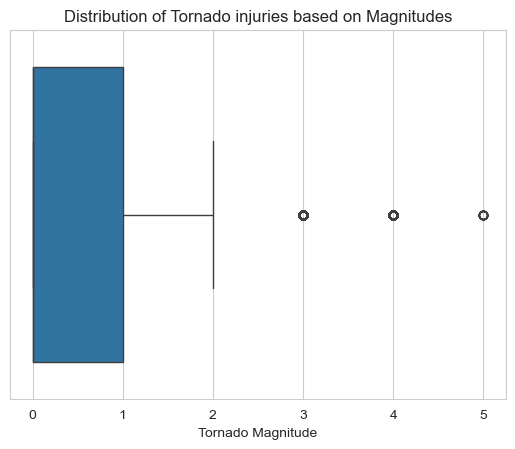

In [61]:
# Looking at the distribution of magnitude of tornados
sns.set_style("whitegrid")
sns.boxplot(x=tornados_df['mag'])

plt.xlabel("Tornado Magnitude")
plt.title("Distribution of Tornado injuries based on Magnitudes")

plt.show()

Based on his boxplot, we can see the median ot tornado magnitudes are 0 and 75% of all recorded tornados are rated 1 or weaker. Since the upper whisker extends to 2, we can see this is the upper boundary for expected tornados. We have 3 invidual tornados are 3, 4, and 5. We can see these are rare events and a majority of tornados are not this extreme.

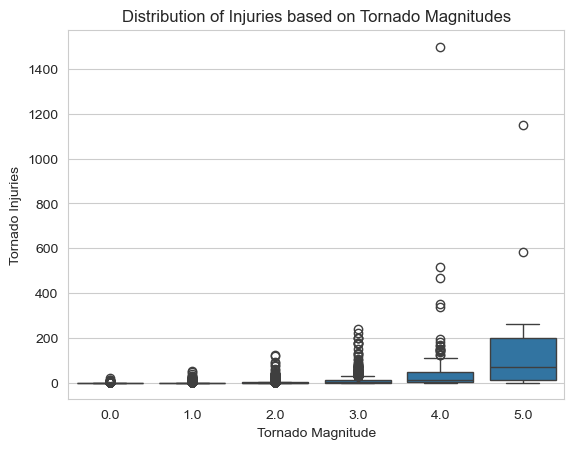

In [85]:
# Look at the distribution of injuries based on tornado magnitudes
sns.set_style("whitegrid")
sns.boxplot(x=tornados_df['mag'], y=tornados_df['inj'])

plt.xlabel("Tornado Magnitude")
plt.ylabel("Tornado Injuries")
plt.title("Distribution of Injuries based on Tornado Magnitudes")

plt.show()

Based on the box and whisker plot above, we can see the spread of tornado's injuries grouped by the tornado magnitude. We can see a clear correlation between tornado magnitude and the spread of injuries. Low magnitude tornados (0.0 to 2.0) result with a median injury near zero with occassional outliers. Higher magnitude events exhibit a dramatic increase in the interquantile range and the median. Both magnitues of 4.0 and 5.0 have wider distributions with more extreme outliers. 

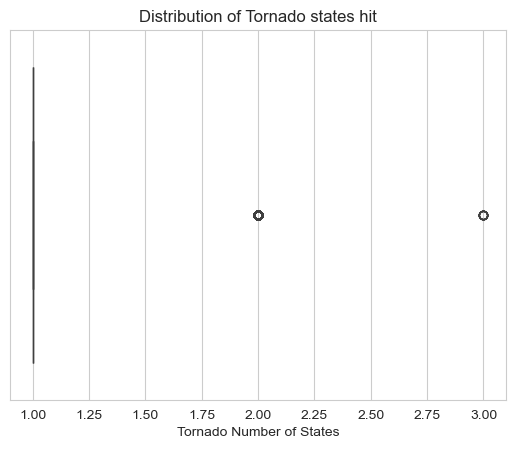

In [64]:
sns.set_style("whitegrid")
sns.boxplot(x=tornados_df['ns'])

plt.xlabel("Tornado Number of States")
plt.title("Distribution of Tornado states hit")

plt.show()

Based on the boxplot above, we can see a vast majority of the tornados remain in one state. But there are 2 outliers that are 2 states and 3 states. Although we can't know based on looking at this graph alone, it would be good to do more research into if this casued more injuries or deaths.

### What is the distribution of variables?

To understand what datapoints will be important, its good to understand the distribution of different variables?

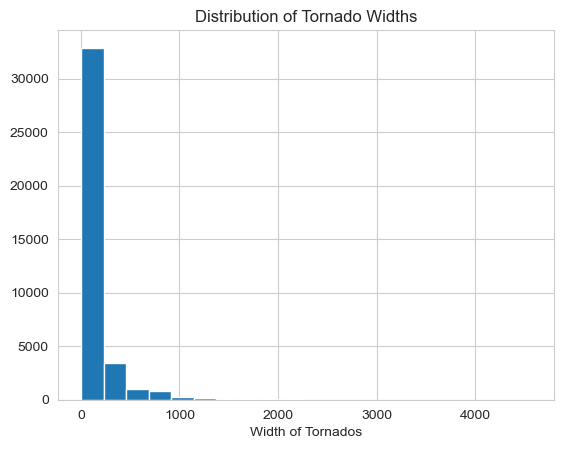

In [88]:
# Understanding the distribution of the width of a tornado
plt.hist(x=tornados_df['wid'], bins = 20)

plt.xlabel("Width of Tornados")
plt.title("Distribution of Tornado Widths")

plt.show()

Based on the above histogram, we can see a heavy right skew distribution. This indicates a vast majority of tornados are narrow. As the width of tornados increase, the amount of tornados decreases.

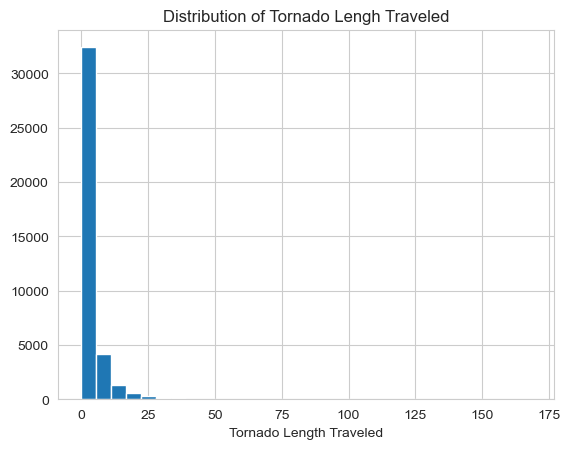

In [90]:
#Understanding the distribution of the fatalities
plt.hist(x=tornados_df['len'], bins = 30)

plt.xlabel("Tornado Length Traveled")
plt.title("Distribution of Tornado Lengh Traveled")

plt.show()

Based on the histogram above, we can see a heavy left skew. A majority fo the tornados do not travel very far. As the distance increases, the number of tornados drops. 